# Symbolische Mathematik

<img src="../01_NUMPY/img/logo.png" width="100%"/><br>
[&larr; Modulübersicht](../00_INTRO.ipynb)

> ☝🏻 Dieses Kapitel ist nicht Teil des Moduls, d. h. lediglich der Vollständigkeit halber bzw. für diesbezüglich Interessierte angefügt.

<center>
    <img src="img/logo_sympy.svg" width=30% />
</center> 

[**SymPy**](https://www.sympy.org/en/index.html) (**Sym**bolic **Py**thon) ist eine Python-Bibliothek für symbolische Mathematik, d. h. für Berechnungen, die nicht numerisch (zahlenmässig) sondern symbolisch ausgewertet werden sollen/müssen. Dabei werden mathematische Ausdrücke/Gleichungen nicht wie in der numerischen Mathematik zahlenmässig ausgewertet bzw. approximiert, sondern immer exakt (in symbolischer Form) verarbeitet. Umgangssprachlich wird dies als "Rechnen mit Buchstaben" bezeichnet.

## 1. Motivation

In gewissen Fällen ist es sehr nützlich, symbolische (exakte) Lösungen für ein mathematisches Problem zu bestimmen, z. B. um eine allgemeine "Formel" für ein bestimmtes Problem (unabhängig von bestimmten Zahlenwerten) zu finden. SymPy ermöglicht das symbolische "Rechnen" in Python.

- [SymPy Homepage](https://docs.sympy.org/latest/index.html)
- [SymPy Reference](https://docs.sympy.org/latest/reference/index.html)

### 1.1 Import

SymPy (Paketname `sympy`) wird üblicherweise mit dem Alias `sm` importiert.

In [1]:
import sympy as sm

## 2. Symbolische Mathematik

In [2]:
sm.sqrt(3) + 1

1 + sqrt(3)

☝🏼 Wie zu Beginn erwähnt, wird der obige Ausdruck nicht numerisch ausgewertet, sondern verbleibt in der symbolischen (exakten) Form. In NumPy würde der Ausdruck `np.sqrt(3) + 1` hingegen numerisch ausgewertet werden (= 2.73..).

### 2.1 Symbolische Variablen

In der Regel wird eine Funktion/Gleichung mit Variablen definiert und kann dann symbolisch verarbeitet/gelöst werden. Diese "mathematischen" Variablen müssen zuerst definiert werden und weisen einen speziellen Datentyp (*Symbol*) auf.

In [5]:
x, a, b, c = sm.symbols('x a b c')  # symbolische Variablen definieren
f = a*x**2 + b*x + c
f

a*x**2 + b*x + c

In [6]:
sm.solveset(f, x)  # Lösung (Nullstellen, f(x) = 0)

{-b/(2*a) - sqrt(-4*a*c + b**2)/(2*a), -b/(2*a) + sqrt(-4*a*c + b**2)/(2*a)}

Sämtliche Operationen werden symbolisch durchgeführt, d. h. es kann problemlos integriert bzw. abgeleitet werden.

In [7]:
sm.integrate(f, x)  # Integration

a*x**3/3 + b*x**2/2 + c*x

In [8]:
sm.diff(f, x)  # Ableitung

2*a*x + b

Möchte man für bestimmte Variablen Zahlenwerte einsetzen, so kann die Methode `subs()` verwendet werden.

In [9]:
f_sub = f.subs({a:1, b:5, c:-20})  # Zahlen einsetzen
f_sub

x**2 + 5*x - 20

Mit `plot()` können symbolische Ausdrücke grafisch dargestellt werden, d. h. man muss keine numerischen Arrays erstellen dafür.

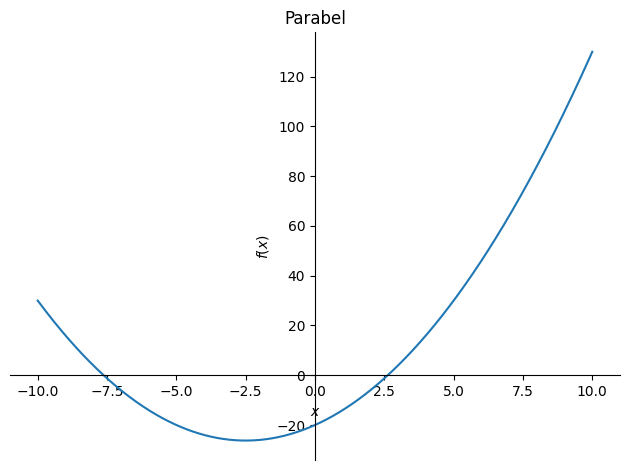

In [10]:
p = sm.plot(f_sub, title='Parabel')

Alle obigen Ausdrücke sind in symbolischer Form und können nicht direkt numerisch ausgewertet werden. Mit der Funktion `lambdify()` kann daraus eine "normale" Funktion generiert werden, welche wie gehabt (mit Zahlen) aufgerufen werden kann.

In [11]:
f_num = sm.lambdify(x, f_sub)
f_num(3.5)

9.75

### 2.2 Vereinfachungen

Zum Umformen/Vereinfachungen von symbolischen Ausdrücken sind die folgenden Funktionen nützlich:

- `simplify()` - allg. Vereinfachung (intelligente Wahl der untenstehenden Funktionen)
- `expand()` - Erweitern
- `factor()` - Faktorisieren
- `collect()` - Ausklammern
- `cancel()` - Kürzen
- `apart()` - Partialbruchzerlegung

In [12]:
sm.simplify(sm.sin(x) / sm.cos(x))

tan(x)

In [13]:
sm.expand((a + 1)**2)

a**2 + 2*a + 1

In [14]:
sm.factor(a**2 + 2*a + 1)

(a + 1)**2

In [15]:
sm.collect(a*x**2 + b*x**2 - b*x + c*x, x)

x**2*(a + b) + x*(-b + c)

In [16]:
sm.cancel((a**2 + 2*a + 1)/(a**2 + a))

(a + 1)/a

In [17]:
sm.apart(x/(x**2 - 1))

1/(2*(x + 1)) + 1/(2*(x - 1))

### 2.3 Differenzialgleichung

Nun folgt ein etwas komplexeres Beispiel, in dem die Differenzialgleichung des $P-T_1$-Gliedes gelöst werden soll, d. h. die Sprungantwort für das $P-T_1$-Glied symbolisch bestimmt werden.

In [18]:
K_P, T_1, t = sm.symbols('K_P T_1 t')
x = sm.symbols('x', cls=sm.Function)
y = 1  # Sprung (könnte auch eine andere Funktion sein, z. B. t für Rampenantwort oder sm.sin(..) für Sinusantwort etc.)

In [19]:
dgl = sm.Eq(T_1*x(t).diff(t) + x(t), K_P * y)  # DGL für P-T1 definieren
dgl

Eq(T_1*Derivative(x(t), t) + x(t), K_P)

In [20]:
x = sm.dsolve(dgl, x(t), ics={x(0): 0})  # DGL lösen
x

Eq(x(t), K_P - K_P*exp(-t/T_1))

In [21]:
x_sub = x.subs({K_P:3, T_1:1})  # Zahlenwerte einsetzen
x_sub

Eq(x(t), 3 - 3*exp(-t))

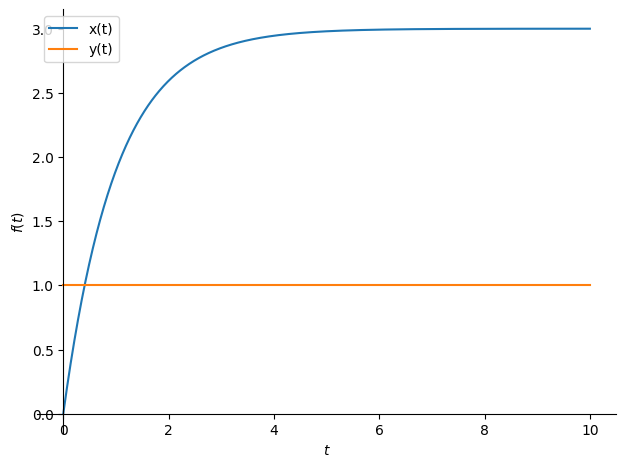

In [22]:
p = sm.plot(x_sub.rhs, (t, 0, 10), label='x(t)', legend=True, show=False)
p.extend(sm.plot(y, (t, 0, 10), label='y(t)', legend=True, show=False))
p.show()

---
<p style='text-align: right; font-size: 70%;'>ABBTS | MAT_AGW | 2025</p>